**Prepare Ordinaray Kriging of Station Observations as Predictor Variables**

leave one cluster out kriging is performed to avoid target leakage to the random forest model to that specific cluster 

In [46]:
#in this section im learning how to implement simple ordinary kriging
from pykrige.ok import OrdinaryKriging
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os   
import geopandas as gpd
from PIL import Image

In [47]:
cwd = os.getcwd()
print(cwd)

c:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Codes


In [48]:
setwd = "C:\\Users\\A S U S\\Documents\\Study\\ClimateData\\CD-Workspace"
df_prec_insitu = pd.read_csv(r"..\Data\Processed\Insitu\insitu_rainfall_1990_2019.csv")
df_prec_insitu['date'] = pd.to_datetime(df_prec_insitu['year'].astype(str) + '-' + df_prec_insitu['month'].astype(str) + '-' + df_prec_insitu['day'].astype(str))
df_prec_insitu = df_prec_insitu.drop(columns=['year', 'month', 'day'])
df_prec_insitu = df_prec_insitu[df_prec_insitu['date'] == '2018-08-04']
df_prec_insitu

,index_no,station_name,district,lat,long,elevation,rainfall_sum,date
10403,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,20.0,2018-08-04
21360,103,Patan_West,Baitadi,29.46714,80.54575,1292.0,5.0,2018-08-04
32317,104,Dadeldhura,Dadeldhura,29.30135,80.58775,1879.0,13.5,2018-08-04
42806,105,Mahendra_Nagar_Sundarpur,Kanchanpur,28.95477,80.23049,197.0,118.2,2018-08-04
53763,107,Darchula_Khalanga,Darchula,29.84496,80.54539,945.0,4.0,2018-08-04
...,...,...,...,...,...,...,...,...
862445,1407,Ilam_Tea_Estate,Ilam,26.90964,87.92308,1208.0,18.7,2018-08-04
873308,1408,Damak,Jhapa,26.67067,87.70318,119.0,0.0,2018-08-04
884144,1412,Chandra_Gadhi,Jhapa,26.56389,88.06150,90.0,13.4,2018-08-04
894527,1416,Kanyam_Tea_Estate,Ilam,26.86806,88.07833,1570.0,4.5,2018-08-04


In [49]:
df_prec_insitu = df_prec_insitu[['lat', 'long', 'rainfall_sum']]
lat = df_prec_insitu['lat'].values
lon = df_prec_insitu['long'].values
prec = df_prec_insitu['rainfall_sum'].values

In [50]:
len(prec)

84

In [53]:
#set up grid for interpolation
roi = gpd.read_file(r"..\Data\Datasets\roi_nepal_rectangle\nepal_rectangle_shape.shp")
lon_min, lat_min, lon_max, lat_max = roi.total_bounds
print(lon_min, lat_min, lon_max, lat_max)

gridx = np.linspace(lon_min, lon_max, 10)
gridy = np.linspace(lat_min, lat_max, 10)

gridx, gridy = np.meshgrid(gridx, gridy)

79.65768442607548 26.184626145596145 88.47970369888858 30.5997204185543


Plotting Enabled

Initializing variogram model...
Coordinates type: 'geographic' 

Using 'gaussian' Variogram Model
Partial Sill: 386.9373135750436
Full Sill: 795.0437502156948
Range: 1.6607772603445663
Nugget: 408.10643664065117 



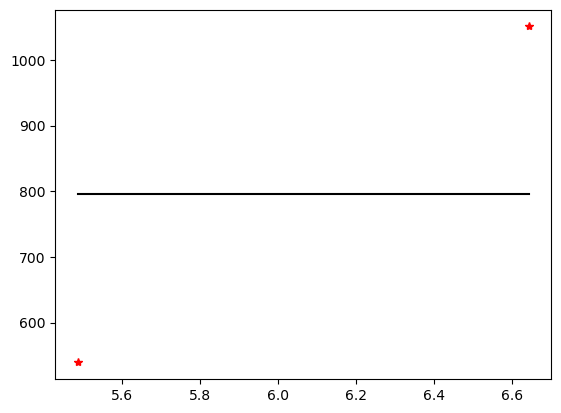

Calculating statistics on variogram model fit...
Executing Ordinary Kriging...



In [54]:
OK = OrdinaryKriging(
    lon,
    lat,
    prec,
    variogram_model='gaussian',
    coordinates_type='geographic',
    verbose=True,
    enable_plotting=True
)
z_interp, ss = OK.execute('grid', gridx, gridy)

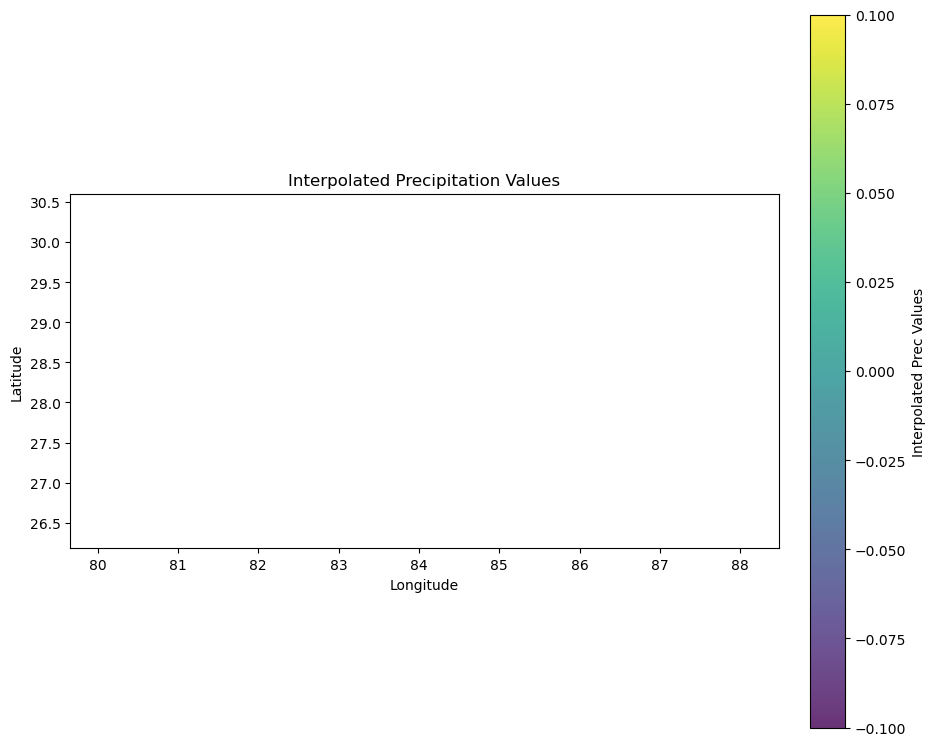

In [55]:
fig, ax = plt.subplots(figsize=(10, 10))
cax = ax.imshow(
    z_interp,
    extent=[
        gridx.min(),
        gridx.max(),
        gridy.min(),
        gridy.max(),
    ],
    origin='lower',
    cmap='viridis',
    alpha=0.8
)
cbar = fig.colorbar(cax, ax = ax, orientation='vertical', fraction=0.046, pad=0.04)
cbar.set_label('Interpolated Prec Values')

ax.set_title('Interpolated Precipitation Values')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.show()



In [ ]:
import numpy as numpy
import pandas as pd
from pykrige.ok import OrdinaryKriging
from joblib import Parallel, delayed

In [ ]:
#fit variogram on whole observations once to get model parameters


In [ ]:
def process_day_loo(day_data, day_date):
    results = []

    #with too few stations, kriging is unstable, returns NaNs or skip
    if len(day_data) < 5:
        return []
    
    

    
